# Transformer-to-VLA

## Diffusion and Flow Models

### Flow Matching：学习连续分布变换

---

**目标**

通过一个简单的概率分布输运问题，理解 Flow Matching 的基本机制。

**核心概念**

- Probability Path
- Velocity Field
- Conditional Flow Matching
- ODE Sampling
- Euler Integration

**实现**

本 Notebook 学习一个连续速度场，使源分布中的样本沿该速度场演化，逼近目标分布。

**学习重点**

理解 Flow Matching 如何学习速度场，并通过求解 ODE 实现连续生成。

## 1. 环境与随机种子

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## 2. 定义起点分布和终点分布

使用历史实验中的设定：

$$
p_0 = \mathcal N(0,1), \qquad p_1 = \mathcal N(4,0.5^2).
$$

区别于 DDPM 的“给数据逐步加噪”，这里从两个分布各自采样，再学习将起始分布变为目标分布的速度场。

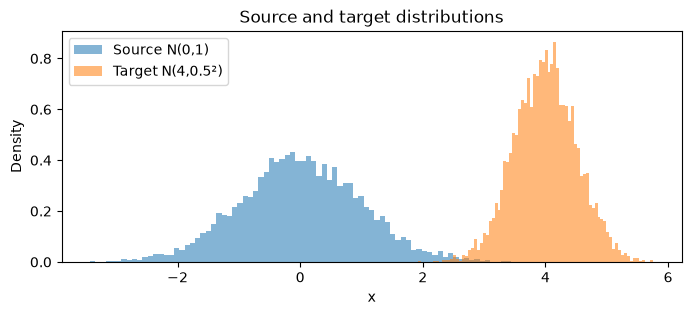

In [2]:
def sample_pairs(batch_size):
    x0 = torch.randn(batch_size, 1, device=device)
    x1 = 4.0 + 0.5 * torch.randn(batch_size, 1, device=device)
    return x0, x1

x0_plot, x1_plot = sample_pairs(6000)
plt.figure(figsize=(8, 3))
plt.hist(x0_plot.cpu().numpy().ravel(), bins=80, density=True, alpha=.55, label="Source N(0,1)")
plt.hist(x1_plot.cpu().numpy().ravel(), bins=80, density=True, alpha=.55, label="Target N(4,0.5²)")
plt.legend(); plt.xlabel("x"); plt.ylabel("Density"); plt.title("Source and target distributions")
plt.show()

## 3. 插值路径与监督速度

对独立采样的配对样本 $x_0,x_1$，令 $t\sim U[0,1]$：

$$
x_t=(1-t)x_0+t x_1, \qquad u_t=x_1-x_0.
$$

这里 $u_t$ 是 **给定样本对的条件速度目标**；神经网络只看到 $(x_t,t)$，最终学到的是在给定位置与时刻下的平均速度场 $v_\theta(x_t,t)$，不等同于记住某一对样本的速度。

*理解检查：当 $t=0$ 时 $x_t=x_0$；当 $t=1$ 时 $x_t=x_1$。*

xt: torch.Size([4, 1]) t: torch.Size([4, 1]) velocity: torch.Size([4, 1])


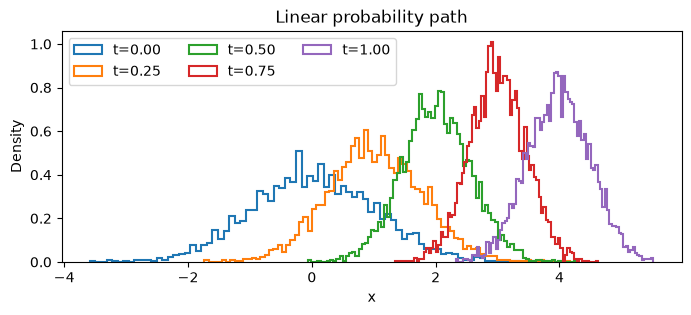

In [3]:
def construct_flow_batch(batch_size):
    x0, x1 = sample_pairs(batch_size)
    t = torch.rand(batch_size, 1, device=device)
    xt = (1 - t) * x0 + t * x1
    target_velocity = x1 - x0
    return xt, t, target_velocity

xt, t, velocity = construct_flow_batch(4)
print("xt:", xt.shape, "t:", t.shape, "velocity:", velocity.shape)

# 显示同一批粒子在几个插值时刻的分布
x0_vis, x1_vis = sample_pairs(4000)
plt.figure(figsize=(8, 3))
for time_value in [0., 0.25, 0.5, 0.75, 1.]:
    xs = ((1-time_value)*x0_vis + time_value*x1_vis).cpu().numpy().ravel()
    plt.hist(xs, bins=85, density=True, histtype="step", linewidth=1.5, label=f"t={time_value:.2f}")
plt.legend(ncol=3); plt.xlabel("x"); plt.ylabel("Density"); plt.title("Linear probability path")
plt.show()

## 4. 最简单的速度预测 MLP

输入为 `[x_t, t]`，输出标量速度 `v_theta(x_t,t)`。保留历史教学实验的 `2 → 64 → 64 → 1` 结构。

In [4]:
class FlowModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 64), nn.ReLU(),
            nn.Linear(64, 64), nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x, t):
        return self.net(torch.cat([x, t], dim=-1))

model = FlowModel().to(device)
print(model)
print("Prediction shape:", model(xt, t).shape)

FlowModel(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)
Prediction shape: torch.Size([4, 1])


## 5. 训练：回归速度场

$$
\mathcal L(\theta)=\mathbb E_{t,x_0,x_1}\left[\lVert v_\theta(x_t,t)-(x_1-x_0)\rVert_2^2\right].
$$

下面保留之前一维入门案例的超参数：`10,000 steps / batch=256 / Adam lr=1e-3`。CPU 可以把 `TRAIN_STEPS` 临时调小以便快速调试。

step  1000/10000: loss=0.85377


step  2000/10000: loss=0.80557


step  3000/10000: loss=0.77726


step  4000/10000: loss=0.76021


step  5000/10000: loss=0.90162


step  6000/10000: loss=0.81139


step  7000/10000: loss=0.88360


step  8000/10000: loss=0.78711


step  9000/10000: loss=0.82307


step 10000/10000: loss=0.79276


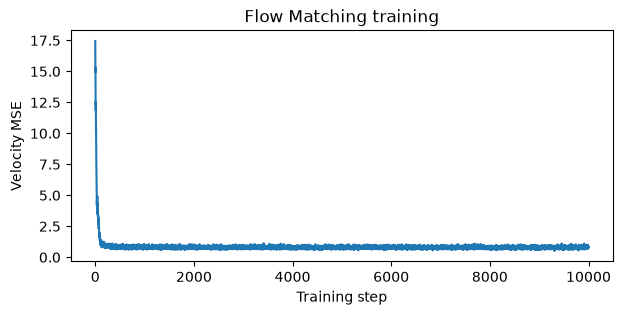

In [5]:
TRAIN_STEPS = 10_000
BATCH_SIZE = 256
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_history = []
model.train()
for step in range(TRAIN_STEPS):
    xt, t, target_velocity = construct_flow_batch(BATCH_SIZE)
    predicted_velocity = model(xt, t)
    loss = ((predicted_velocity - target_velocity) ** 2).mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if (step + 1) % max(1, TRAIN_STEPS // 10) == 0:
        print(f"step {step+1:5d}/{TRAIN_STEPS}: loss={loss.item():.5f}")

plt.figure(figsize=(7, 3))
plt.plot(loss_history)
plt.xlabel("Training step"); plt.ylabel("Velocity MSE"); plt.title("Flow Matching training")
plt.show()

## 6. Euler 采样：把学习到的速度场积分起来

训练结束后，用模型构造如下常微分方程：

$$
\frac{dx}{dt}=v_\theta(x,t),\qquad x(0)\sim\mathcal N(0,1).
$$

使用显式 Euler 方法，令 $\Delta t=1/N$，逐步更新 $x_{k+1}=x_k+v_\theta(x_k,t_k)\Delta t$。注意这里的 $t$ 表示 **Flow 时间**，不是 DDPM 的噪声时间索引。

Generated: mean=4.055, std=0.516
Target: mean=4.000, std=0.500


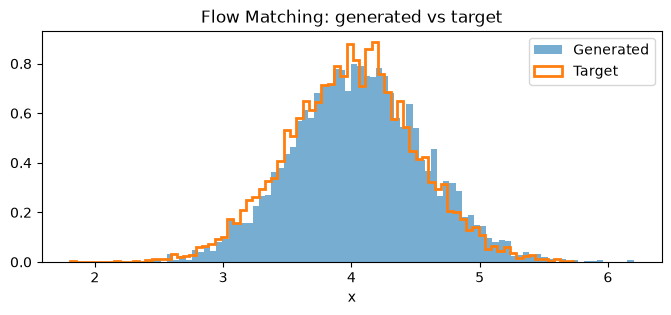

In [6]:
@torch.no_grad()
def sample_flow(n=5000, steps=100, return_history=False):
    model.eval()
    x = torch.randn(n, 1, device=device)
    snapshots = {0: x.detach().cpu().clone()} if return_history else None
    if steps < 1:
        raise ValueError("steps must be positive")
    dt = 1.0 / steps
    for i in range(steps):
        t = torch.full_like(x, i / steps)
        x = x + model(x, t) * dt
        if return_history and (i + 1) in [steps//4, steps//2, 3*steps//4, steps]:
            snapshots[i + 1] = x.detach().cpu().clone()
    return (x.cpu(), snapshots) if return_history else x.cpu()

NUM_ODE_STEPS = 100
samples, snapshots = sample_flow(steps=NUM_ODE_STEPS, return_history=True)
values = samples.numpy().ravel()
print(f"Generated: mean={values.mean():.3f}, std={values.std():.3f}")
print("Target: mean=4.000, std=0.500")
plt.figure(figsize=(8, 3))
plt.hist(values, bins=80, density=True, alpha=.6, label="Generated")
reference = np.random.default_rng(SEED).normal(4., .5, size=6000)
plt.hist(reference, bins=80, density=True, histtype="step", linewidth=2, label="Target")
plt.legend(); plt.title("Flow Matching: generated vs target"); plt.xlabel("x"); plt.show()

## 7. 观察采样过程中分布的变化

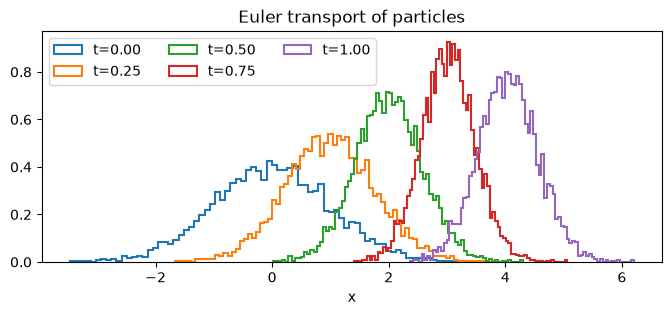

In [7]:
plt.figure(figsize=(8, 3))
total_steps = max(snapshots)
for step_idx, particle_state in sorted(snapshots.items()):
    plt.hist(particle_state.numpy().ravel(), bins=80, density=True, histtype="step", linewidth=1.5, label=f"t={step_idx/total_steps:.2f}")
plt.legend(ncol=3); plt.title("Euler transport of particles"); plt.xlabel("x"); plt.show()

## 8. 回顾与下一步

- **数据构造**：先分别采样 $x_0,x_1$，然后选取随机时间 $t$。
- **训练目标**：预测条件路径的速度 $x_1-x_0$，不是预测 DDPM 的噪声 $\epsilon$。
- **生成过程**：随机采样源分布，通过 Euler 数值积分得到目标分布。
- **下一步**：在相同的二维圆环 / 八聚类数据上实现 Flow Matching，再过渡到机器人条件动作序列。

**练习**：把 `NUM_ODE_STEPS=100` 改为 `10` 或 `200`；把目标分布均值从 4 改成 -3；观察最终均值和方差的变化。